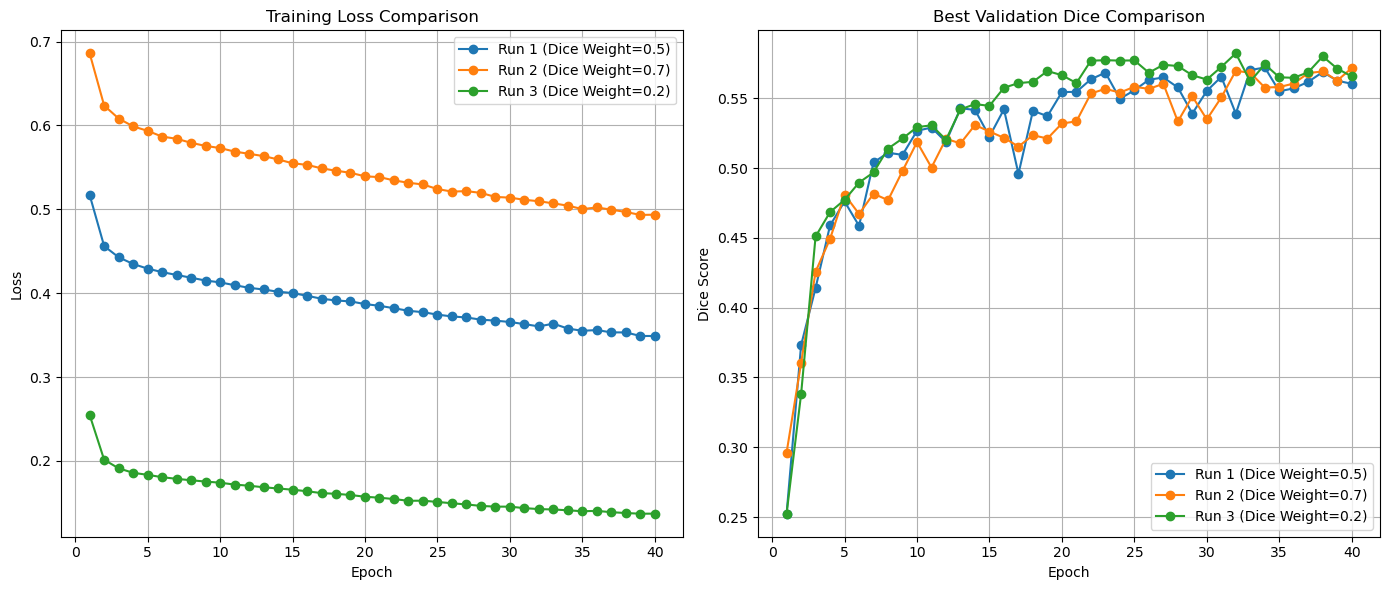

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import os


metrics_files = {
    "Run 1 (Dice Weight=0.5)": "Output/model01_dicebce0.5_loss/training_validation_metrics.csv",
    "Run 2 (Dice Weight=0.7)": "Output/model01_dicebce0.7_loss/training_validation_metrics.csv",
    "Run 3 (Dice Weight=0.2)": "Output/model01_dicebce0.2_loss/training_validation_metrics.csv"
}

fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

ax1.set_title("Training Loss Comparison")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.grid(True)
ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

ax2.set_title("Best Validation Dice Comparison")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Dice Score")
ax2.grid(True)
ax2.xaxis.set_major_locator(MaxNLocator(integer=True))

# 3. Process and plot each file
for label, filepath in metrics_files.items():
    if not os.path.exists(filepath):
        print(f"Warning: File not found: {filepath}. Skipping '{label}'.")
        continue
        
    df = pd.read_csv(filepath)
    
    # Group by epoch to handle the multiple threshold rows per epoch
    # We take the 'first' loss (since it's identical across thresholds) 
    # and the 'max' dice score achieved in that epoch
    epoch_summary = df.groupby("epoch").agg(
        train_loss=("avg_train_loss", "first"),
        best_dice=("dice", "max")
    ).reset_index()
    
    # Plot Loss
    ax1.plot(epoch_summary["epoch"], epoch_summary["train_loss"], marker='o', label=label)
    
    # Plot Dice
    ax2.plot(epoch_summary["epoch"], epoch_summary["best_dice"], marker='o', label=label)

# 4. Add legends and show
ax1.legend()
ax2.legend()
plt.tight_layout()
plt.show()

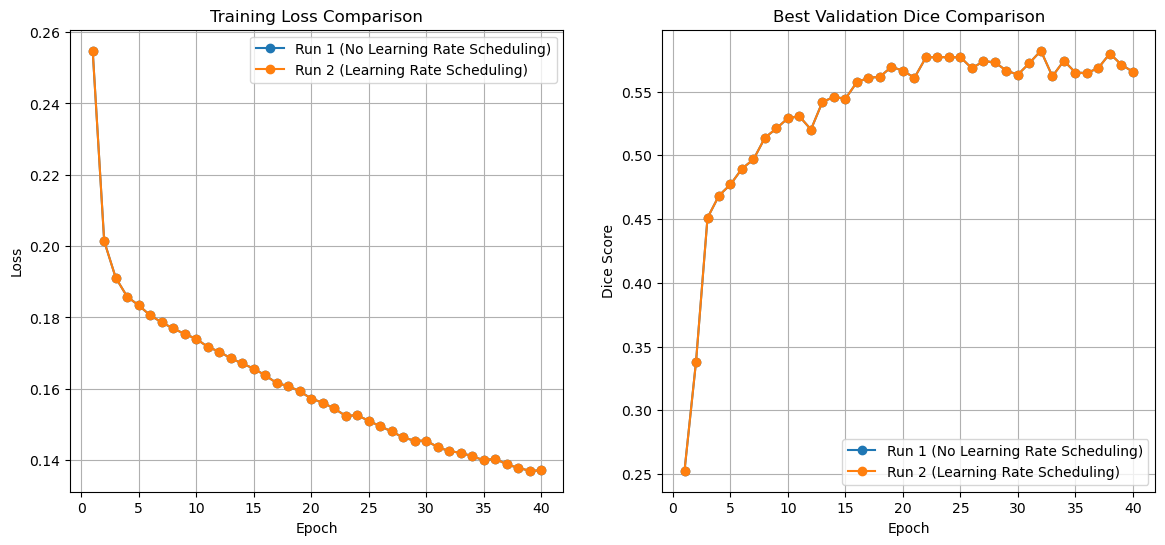

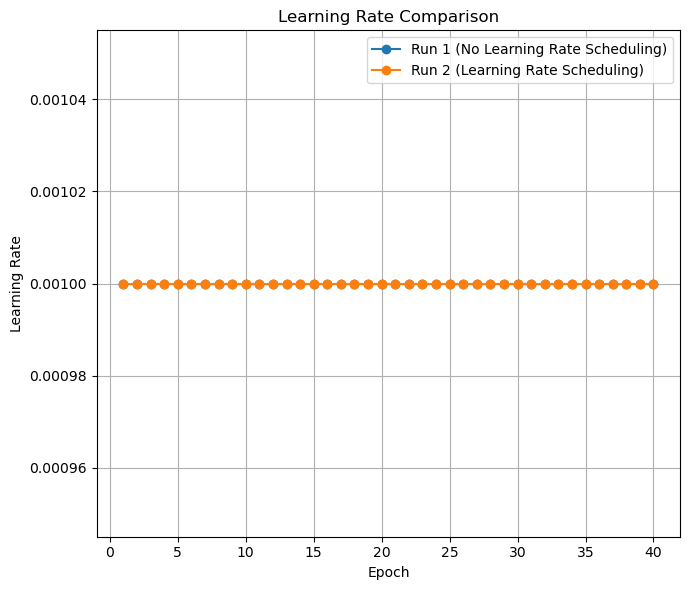

In [2]:
metrics_files = {
    "Run 1 (No Learning Rate Scheduling)": "Output/model01_dicebce0.2_loss/training_validation_metrics.csv",
    "Run 2 (Learning Rate Scheduling)": "Output/model01_dicebce0.2_loss_scheduler/training_validation_metrics.csv",
}    

fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
fig2, ax3 = plt.subplots(figsize=(7, 6))

ax1.set_title("Training Loss Comparison")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.grid(True)
ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

ax2.set_title("Best Validation Dice Comparison")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Dice Score")
ax2.grid(True)
ax2.xaxis.set_major_locator(MaxNLocator(integer=True))

ax3.set_title("Learning Rate Comparison")
ax3.set_xlabel("Epoch")
ax3.set_ylabel("Learning Rate")
ax3.grid(True)  
ax3.xaxis.set_major_locator(MaxNLocator(integer=True))

# 3. Process and plot each file
for label, filepath in metrics_files.items():
    if not os.path.exists(filepath):
        print(f"Warning: File not found: {filepath}. Skipping '{label}'.")
        continue
        
    df = pd.read_csv(filepath)
    
    # Group by epoch to handle the multiple threshold rows per epoch
    # We take the 'first' loss (since it's identical across thresholds) 
    # and the 'max' dice score achieved in that epoch
    epoch_summary = df.groupby("epoch").agg(
        train_loss=("avg_train_loss", "first"),
        best_dice=("dice", "max")
    ).reset_index().head(40)

    if "Run 1" in label or "learning_rate" not in epoch_summary.columns:
        epoch_summary["learning_rate"] = 1e-3
    
    # Plot Loss
    ax1.plot(epoch_summary["epoch"], epoch_summary["train_loss"], marker='o', label=label)
    
    # Plot Dice
    ax2.plot(epoch_summary["epoch"], epoch_summary["best_dice"], marker='o', label=label)

    # Plot Learning Rate
    ax3.plot(epoch_summary["epoch"], epoch_summary["learning_rate"], marker='o', label=label)

# 4. Add legends and show
ax1.legend()
ax2.legend()
ax3.legend()
plt.tight_layout()
plt.show()

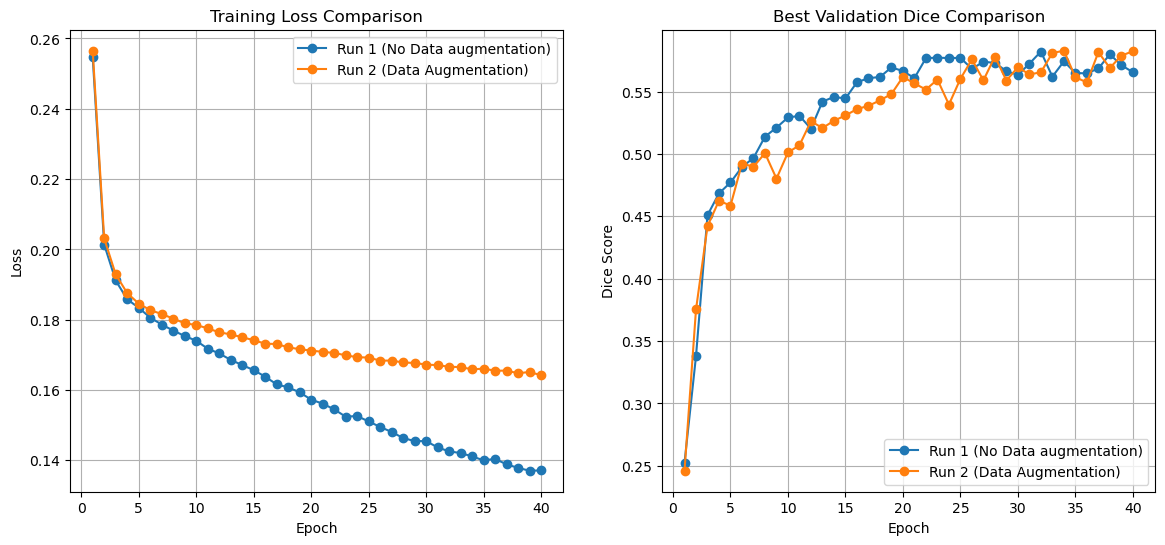

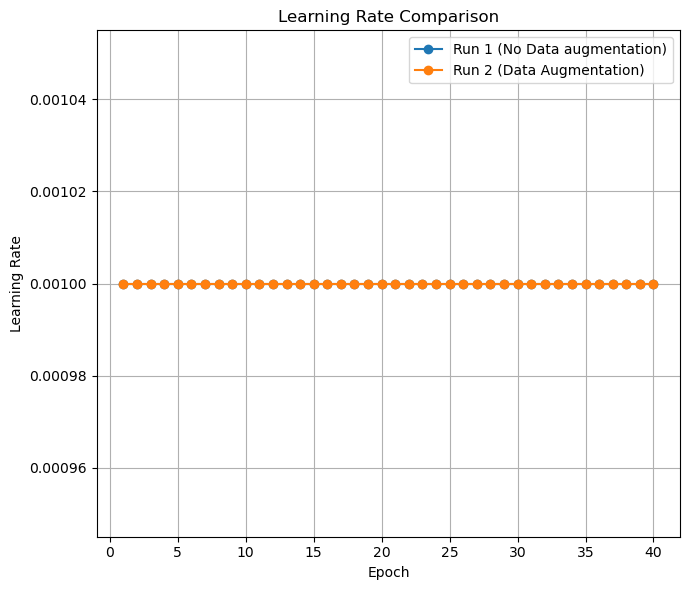

In [3]:
metrics_files = {
    "Run 1 (No Data augmentation)": "Output/model01_dicebce0.2_loss_scheduler/training_validation_metrics.csv",
    "Run 2 (Data Augmentation)": "Output/model01_dicebce0.2_loss_scheduler_augmented/training_validation_metrics.csv"
}

fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
fig2, ax3 = plt.subplots(figsize=(7, 6))

ax1.set_title("Training Loss Comparison")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.grid(True)
ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

ax2.set_title("Best Validation Dice Comparison")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Dice Score")
ax2.grid(True)
ax2.xaxis.set_major_locator(MaxNLocator(integer=True))

ax3.set_title("Learning Rate Comparison")
ax3.set_xlabel("Epoch")
ax3.set_ylabel("Learning Rate")
ax3.grid(True)
ax3.xaxis.set_major_locator(MaxNLocator(integer=True))

# 3. Process and plot each file
for label, filepath in metrics_files.items():
    if not os.path.exists(filepath):
        print(f"Warning: File not found: {filepath}. Skipping '{label}'.")
        continue
        
    df = pd.read_csv(filepath)
    
    # Group by epoch to handle the multiple threshold rows per epoch
    # We take the 'first' loss (since it's identical across thresholds) 
    # and the 'max' dice score achieved in that epoch
    epoch_summary = df.groupby("epoch").agg(
        train_loss=("avg_train_loss", "first"),
        best_dice=("dice", "max"),
        learning_rate=("learning_rate", "first")
    ).reset_index().head(40)
    
    # Plot Loss
    ax1.plot(epoch_summary["epoch"], epoch_summary["train_loss"], marker='o', label=label)
    
    # Plot Dice
    ax2.plot(epoch_summary["epoch"], epoch_summary["best_dice"], marker='o', label=label)

    # Plot Learning Rate
    ax3.plot(epoch_summary["epoch"], epoch_summary["learning_rate"], marker='o', label=label)


# 4. Add legends and show
ax1.legend()
ax2.legend()
ax3.legend()
plt.tight_layout()
plt.show()



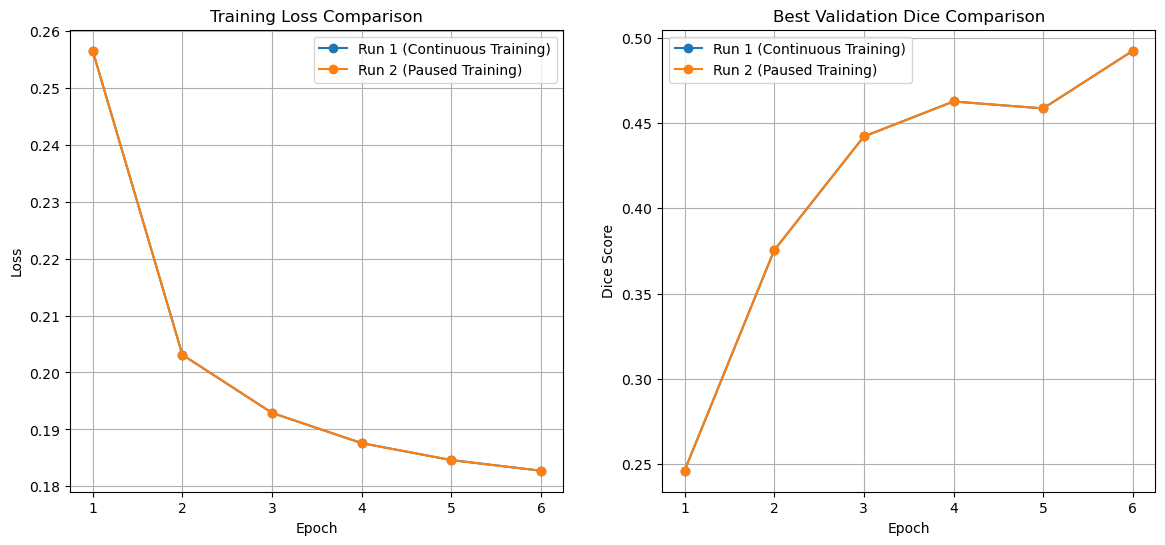

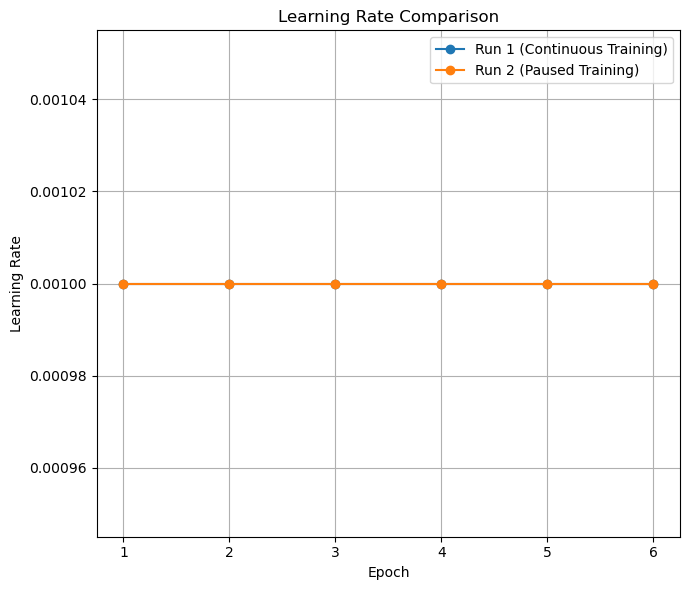

In [4]:
metrics_files = {
    "Run 1 (Continuous Training)": "Output/model01_continuity_test_full/training_validation_metrics.csv",
    "Run 2 (Paused Training)": "Output/model01_continuity_test_continued_max_6_from_3/training_validation_metrics.csv"
}

fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
fig2, ax3 = plt.subplots(figsize=(7, 6))

ax1.set_title("Training Loss Comparison")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.grid(True)
ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

ax2.set_title("Best Validation Dice Comparison")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Dice Score")
ax2.grid(True)
ax2.xaxis.set_major_locator(MaxNLocator(integer=True))

ax3.set_title("Learning Rate Comparison")
ax3.set_xlabel("Epoch")
ax3.set_ylabel("Learning Rate")
ax3.grid(True)
ax3.xaxis.set_major_locator(MaxNLocator(integer=True))

# 3. Process and plot each file
for label, filepath in metrics_files.items():
    if not os.path.exists(filepath):
        print(f"Warning: File not found: {filepath}. Skipping '{label}'.")
        continue
        
    df = pd.read_csv(filepath)
    
    # Group by epoch to handle the multiple threshold rows per epoch
    # We take the 'first' loss (since it's identical across thresholds) 
    # and the 'max' dice score achieved in that epoch
    epoch_summary = df.groupby("epoch").agg(
        train_loss=("avg_train_loss", "first"),
        best_dice=("dice", "max"),
        learning_rate=("learning_rate", "first")
    ).reset_index().head(6)
    
    # Plot Loss
    ax1.plot(epoch_summary["epoch"], epoch_summary["train_loss"], marker='o', label=label)
    
    # Plot Dice
    ax2.plot(epoch_summary["epoch"], epoch_summary["best_dice"], marker='o', label=label)

    # Plot Learning Rate
    ax3.plot(epoch_summary["epoch"], epoch_summary["learning_rate"], marker='o', label=label)


# 4. Add legends and show
ax1.legend()
ax2.legend()
ax3.legend()
plt.tight_layout()
plt.show()

